  FARM_ID CROP_TYPE  YIELD_KG  AREA_ACRES HARVEST_DATE    DISTRICT SEASON  \
0    F001     Wheat    1500.0         4.0   01/01/2023     Sialkot   Rabi   
1    F002     Wheat    1500.0         5.0   02/01/2023      Multan   Rabi   
2    F003     Wheat    2500.0         5.0   03/01/2023  Faisalabad   Rabi   
3    F004     Wheat    1500.0         NaN   04/01/2023      Multan   Rabi   
4    F005      Rice    1500.0         4.0   05/01/2023  Faisalabad   Rabi   
5    F006      Rice    2000.0         6.0   06/01/2023  Faisalabad   Rabi   
6    F007     Maize    1500.0         6.0   07/01/2023  Faisalabad   Rabi   
7    F008     Wheat    1500.0         5.0   08/01/2023      Lahore   Rabi   
8    F009     Wheat    2000.0         5.0   09/01/2023  Faisalabad   Rabi   
9    F010     Wheat    1500.0         3.0   10/01/2023  Faisalabad   Rabi   

  FERTILIZER_USED  YIELD_VALUE  
0             Yes        30000  
1              No        30000  
2             Yes        50000  
3             Yes   

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_6040\4036117128.py:16: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  print(crop_df.describe(include="object"))


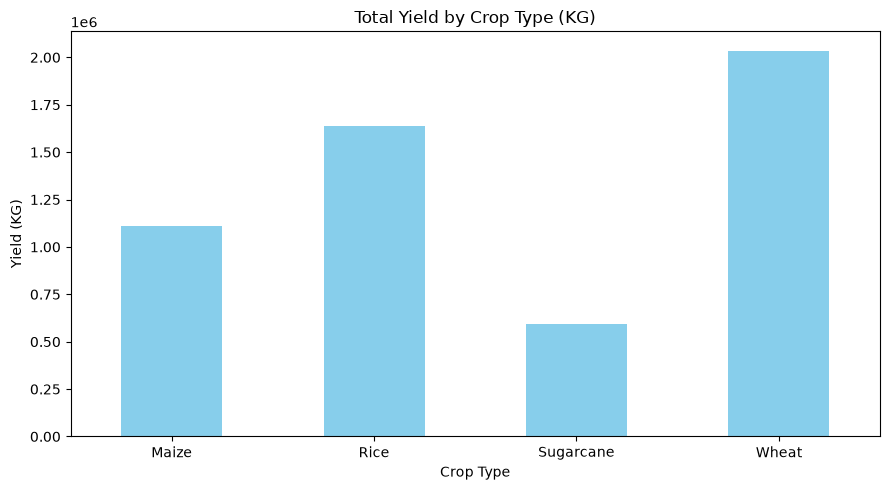

              YIELD_KG
HARVEST_DATE          
2023-01-01      1500.0
2023-01-02      1500.0
2023-01-03      2500.0
2023-01-04      1500.0
2023-01-05      1500.0
...                ...
2031-03-15      1500.0
2031-03-16      2000.0
2031-03-17      2000.0
2031-03-18      2000.0
2031-03-19      2500.0

[2670 rows x 1 columns]


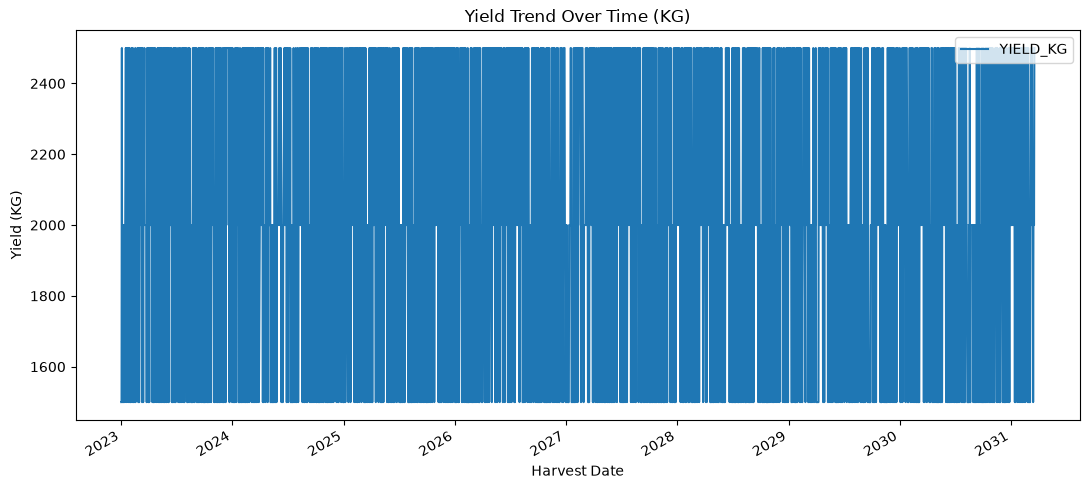

In [11]:
import pandas as pd
import numpy as up
import matplotlib.pyplot as plt

crop_df = pd.read_csv("crop_yield.csv")


print(crop_df.head(10))

print(crop_df.isnull().sum())

print(crop_df.dtypes)

print(crop_df.describe())

print(crop_df.describe(include="object"))

crop_df = crop_df.dropna(subset=["YIELD_KG"])

crop_df["AREA_ACRES"] = crop_df["AREA_ACRES"].fillna(
    crop_df["AREA_ACRES"].mean()
)

crop_df["DISTRICT"] = crop_df["DISTRICT"].fillna("Unknown")

crop_df["FERTILIZER_USED"] = crop_df["FERTILIZER_USED"].fillna("No")

crop_df["YIELD_VALUE"] = crop_df["YIELD_VALUE"].fillna(
    crop_df["YIELD_VALUE"].mean()
)


crop_df["HARVEST_DATE"] = pd.to_datetime(
    crop_df["HARVEST_DATE"],
    format="%d/%m/%Y",
    errors="coerce"
)

crop_df["FARM_ID"] = (
    crop_df["FARM_ID"].astype(str).str.replace("F", "", regex=False).astype(int)
)

print(crop_df.isnull().sum())

print(crop_df.dtypes)

crop_yield = crop_df.groupby("CROP_TYPE")["YIELD_KG"].sum()
print(crop_yield)

crop_yield.plot(kind="bar", figsize=(9, 5), color="skyblue")
plt.title("Total Yield by Crop Type (KG)")
plt.xlabel("Crop Type")
plt.ylabel("Yield (KG)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

yield_pivot = crop_df.pivot_table(
    values="YIELD_KG",
    index="HARVEST_DATE",
    aggfunc="sum"
)
print(yield_pivot)

yield_pivot.plot(
    kind="line",
    figsize=(11, 5),
    title="Yield Trend Over Time (KG)"
)
plt.xlabel("Harvest Date")
plt.ylabel("Yield (KG)")
plt.tight_layout()
plt.savefig("crop_yield_trend.png", dpi=300, bbox_inches="tight")
plt.show()